In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_recall_curve,
    average_precision_score,
)

# 1. Load dataset
df = pd.read_csv("../data/ai4i2020.csv")

# 2. Physics-Informed Features (matching Notebook 01)
df["Angular_velocity_rad_s"] = df["Rotational speed [rpm]"] * (2 * np.pi / 60)
df["Power_W"] = df["Torque [Nm]"] * df["Angular_velocity_rad_s"]
df["Temp_diff_K"] = df["Process temperature [K]"] - df["Air temperature [K]"]
df["Overstrain_proxy"] = df["Torque [Nm]"] * df["Tool wear [min]"]

# 3. Encode categorical machine quality Type (L=0, M=1, H=2)
df["Type_encoded"] = df["Type"].map({"L": 0, "M": 1, "H": 2})

# 4. Define Features (X) and Target (y)
# CRITICAL: Drop IDs, raw 'Type', target, and sub-failure columns (leakage!)
drop_cols = [
    "UDI",
    "Product ID",
    "Type",
    "Machine failure",
    "TWF",
    "HDF",
    "PWF",
    "OSF",
    "RNF",
]

X = df.drop(columns=drop_cols)
y = df["Machine failure"]

# Clean column names for XGBoost (removes brackets like [K], [Nm])
X.columns = [
    col.replace("[", "").replace("]", "").replace(" ", "_") for col in X.columns
]

# 5. Stratified Train-Test Split (80/20)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Training samples: {X_train.shape[0]} | Failures: {y_train.sum()}")
print(f"Testing samples:  {X_test.shape[0]}  | Failures: {y_test.sum()}")

Training samples: 8000 | Failures: 271
Testing samples:  2000  | Failures: 68


In [2]:
# Calculate imbalance ratio for XGBoost
neg_count = (y_train == 0).sum()
pos_count = (y_train == 1).sum()
scale_pos_weight = neg_count / pos_count
print(f"Computed scale_pos_weight: {scale_pos_weight:.2f}\n")

# Model 1: Baseline Random Forest
rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=12,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1,
)
rf_model.fit(X_train, y_train)
rf_preds = rf_model.predict(X_test)
rf_probs = rf_model.predict_proba(X_test)[:, 1]

# Model 2: XGBoost Classifier
xgb_model = XGBClassifier(
    n_estimators=300,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_pos_weight,
    eval_metric="aucpr",
    random_state=42,
    n_jobs=-1,
)
xgb_model.fit(X_train, y_train)
xgb_preds = xgb_model.predict(X_test)
xgb_probs = xgb_model.predict_proba(X_test)[:, 1]

# Print Classification Reports
print("=== RANDOM FOREST REPORT ===")
print(classification_report(y_test, rf_preds, target_names=["Healthy", "Failure"]))
print(f"RF PR-AUC:  {average_precision_score(y_test, rf_probs):.4f}\n")

print("=== XGBOOST REPORT ===")
print(classification_report(y_test, xgb_preds, target_names=["Healthy", "Failure"]))
print(f"XGB PR-AUC: {average_precision_score(y_test, xgb_probs):.4f}")

Computed scale_pos_weight: 28.52

=== RANDOM FOREST REPORT ===
              precision    recall  f1-score   support

     Healthy       0.99      0.99      0.99      1932
     Failure       0.72      0.85      0.78        68

    accuracy                           0.98      2000
   macro avg       0.86      0.92      0.88      2000
weighted avg       0.99      0.98      0.98      2000

RF PR-AUC:  0.8703

=== XGBOOST REPORT ===
              precision    recall  f1-score   support

     Healthy       0.99      0.99      0.99      1932
     Failure       0.80      0.82      0.81        68

    accuracy                           0.99      2000
   macro avg       0.90      0.91      0.90      2000
weighted avg       0.99      0.99      0.99      2000

XGB PR-AUC: 0.8926


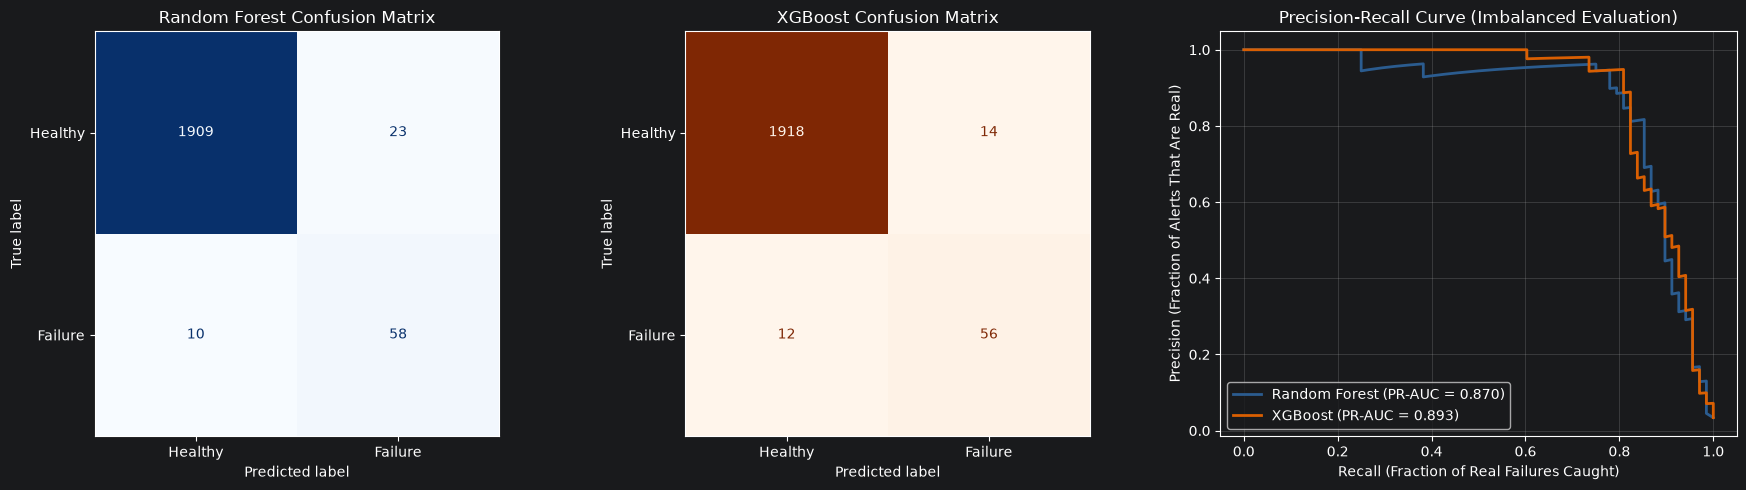

In [3]:
import os
os.makedirs("../results", exist_ok=True)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Random Forest Confusion Matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    rf_preds,
    display_labels=["Healthy", "Failure"],
    cmap="Blues",
    colorbar=False,
    ax=axes[0],
)
axes[0].set_title("Random Forest Confusion Matrix")

# 2. XGBoost Confusion Matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    xgb_preds,
    display_labels=["Healthy", "Failure"],
    cmap="Oranges",
    colorbar=False,
    ax=axes[1],
)
axes[1].set_title("XGBoost Confusion Matrix")

# 3. Precision-Recall Curve Comparison
for name, probs, color in [
    ("Random Forest", rf_probs, "#2b5c8f"),
    ("XGBoost", xgb_probs, "#d95f02"),
]:
    precision, recall, _ = precision_recall_curve(y_test, probs)
    ap = average_precision_score(y_test, probs)
    axes[2].plot(recall, precision, label=f"{name} (PR-AUC = {ap:.3f})", color=color, lw=2)

axes[2].set_title("Precision-Recall Curve (Imbalanced Evaluation)")
axes[2].set_xlabel("Recall (Fraction of Real Failures Caught)")
axes[2].set_ylabel("Precision (Fraction of Alerts That Are Real)")
axes[2].legend(loc="lower left")
axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.savefig("../results/model_comparison.png", dpi=300)
plt.show()

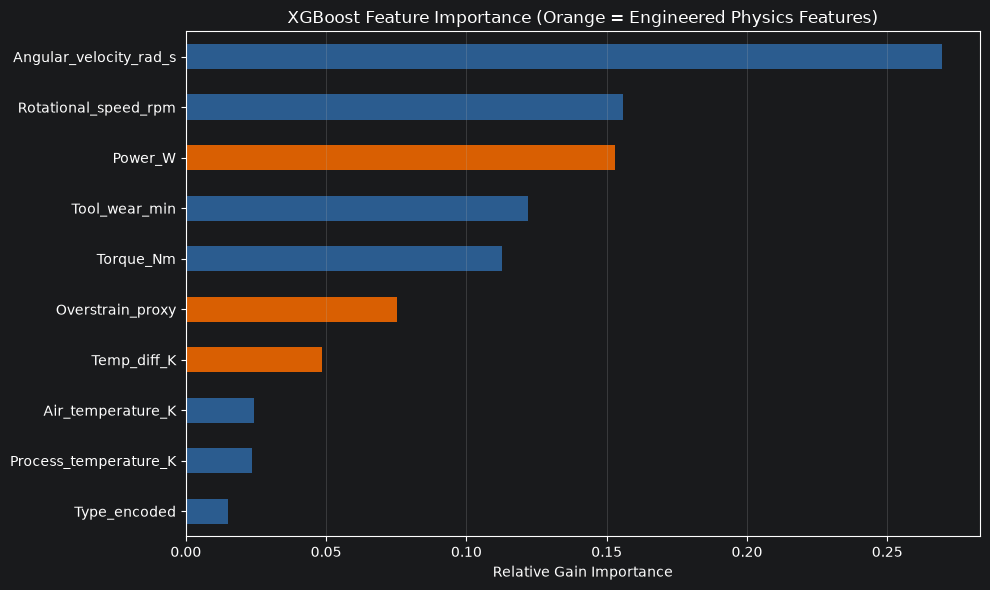

In [4]:
importances = pd.Series(xgb_model.feature_importances_, index=X.columns).sort_values(
    ascending=True
)

plt.figure(figsize=(10, 6))
colors = [
    "#d95f02" if feat in ["Power_W", "Temp_diff_K", "Overstrain_proxy"] else "#2b5c8f"
    for feat in importances.index
]
importances.plot(kind="barh", color=colors)
plt.title("XGBoost Feature Importance (Orange = Engineered Physics Features)")
plt.xlabel("Relative Gain Importance")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.savefig("../results/feature_importance.png", dpi=300)
plt.show()